In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Set style
sns.set_theme(style="whitegrid")

# Define paths
DATA_DIR = 'data_csv'
VAR_DATA_PATH = os.path.join(DATA_DIR, 'var_data.csv')
VISUALS_DATA_PATH = os.path.join(DATA_DIR, 'visual_data.csv')

# --- Helper Functions ---
def load_data(path):
    """Loads CSV data with date parsing."""
    if not os.path.exists(path):
        print(f"File not found: {path}")
        return None
    return pd.read_csv(path, index_col=0, parse_dates=True)

def plot_series(data, x=None, y=None, title=None, ylabel=None, xlabel='Year', xlim_right=None, figsize=(12, 6), palette=None, linewidth=2.5):
    """Generic plotting function for time series."""
    plt.figure(figsize=figsize)
    sns.lineplot(data=data, x=x, y=y, palette=palette, linewidth=linewidth)
    if title: plt.title(title)
    if ylabel: plt.ylabel(ylabel)
    if xlabel: plt.xlabel(xlabel)
    if xlim_right: plt.xlim(right=pd.Timestamp(xlim_right))
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

In [2]:
# Load Data
df_var = load_data(VAR_DATA_PATH)

if df_var is not None:
    print("Data Loaded Successfully.")
    print("VAR Data Range:", df_var.index.min(), "to", df_var.index.max())
    print("Columns:", df_var.columns.tolist())

Data Loaded Successfully.
VAR Data Range: 1987-01-01 00:00:00 to 2007-07-01 00:00:00
Columns: ['cs', 'cs10', 'pce', 'ffr', 'unemp', 'atlanta', 'boston', 'charlotte', 'chicago', 'cleveland', 'dallas', 'denver', 'detroit', 'las vegas', 'los angeles', 'miami', 'minneapolis', 'new york', 'phoenix', 'portland', 'san diego', 'san francisco', 'seattle', 'tampa', 'washington']


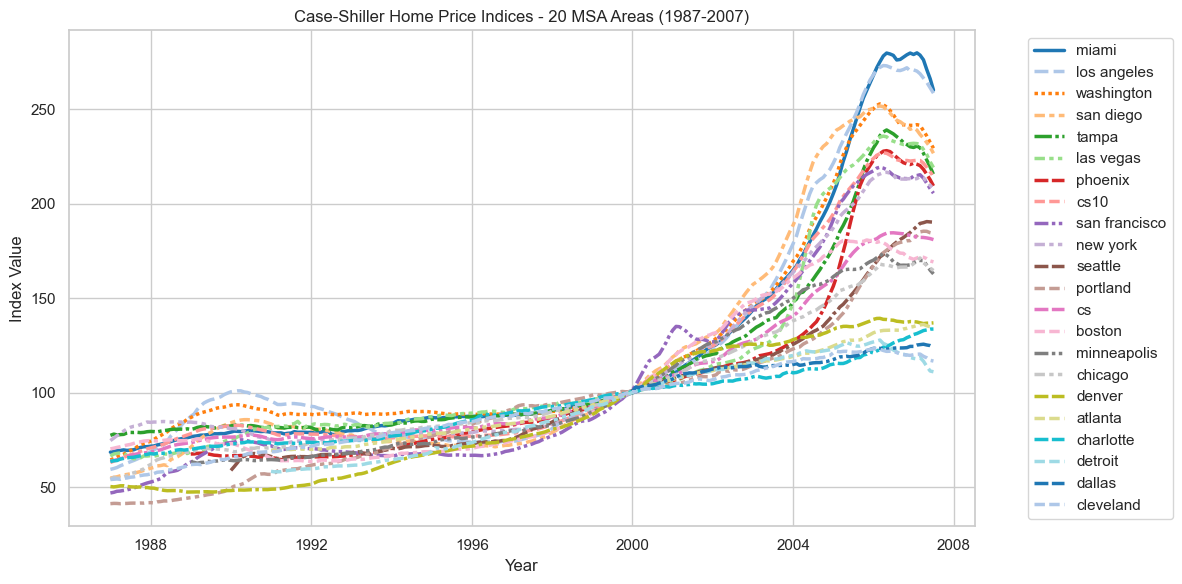

In [7]:
# Define the 20 MSA columns (Case-Shiller Indices)
# Based on the data download script, these are the lowercase city names
msa_columns = [
    'atlanta', 'boston', 'charlotte', 'chicago', 'cleveland', 
    'dallas', 'denver', 'detroit', 'las vegas', 'los angeles', 
    'miami', 'minneapolis', 'new york', 'phoenix', 'portland', 
    'san diego', 'san francisco', 'seattle', 'tampa', 'washington', 'cs', 'cs10']

# Verify columns exist in the dataframe
available_msa_cols = [col for col in msa_columns if col in df_var.columns]
missing_msa_cols = [col for col in msa_columns if col not in df_var.columns]

if missing_msa_cols:
    print(f"Warning: The following MSA columns are missing: {missing_msa_cols}")

# Plot all MSA Case-Shiller Indices
if available_msa_cols:
    # Sort columns by their maximum value (descending) to order the legend
    sorted_cols = df_var[available_msa_cols].max().sort_values(ascending=False).index.tolist()

    plot_series(
        df_var[sorted_cols], 
        title='Case-Shiller Home Price Indices - 20 MSA Areas (1987-2007)', 
        ylabel='Index Value',
        palette='tab20' # Using a palette with many distinct colors
    )
else:
    print("No MSA columns found to plot.")

Visuals Data Loaded Successfully.
Visuals Data Range: 1959-01-01 00:00:00 to 2025-08-01 00:00:00


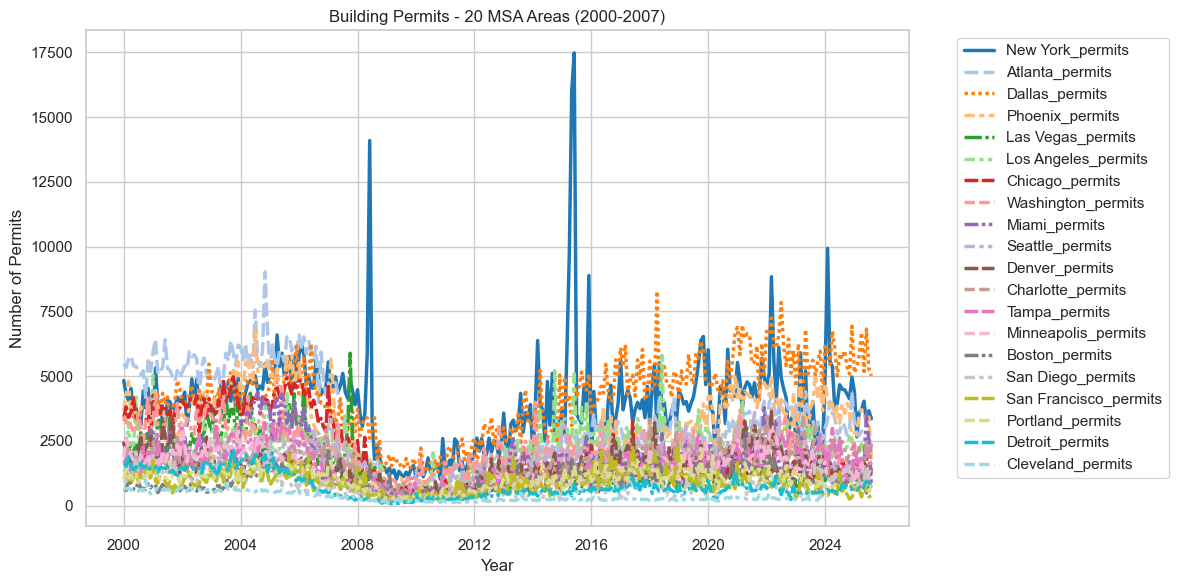

In [4]:
# Define path for visuals data
# VISUALS_DATA_PATH is already defined at the top

# Load Visuals Data
df_visuals = load_data(VISUALS_DATA_PATH)

if df_visuals is not None:
    print("Visuals Data Loaded Successfully.")
    print("Visuals Data Range:", df_visuals.index.min(), "to", df_visuals.index.max())
    
    # Identify MSA Permit columns (excluding National)
    # The columns are formatted as 'City_permits'
    permits_columns = [col for col in df_visuals.columns if '_permits' in col and 'National' not in col]
    
    if permits_columns:
        # Sort columns by their maximum value (descending) to order the legend
        sorted_permits_cols = df_visuals[permits_columns].max().sort_values(ascending=False).index.tolist()

        plot_series(
            df_visuals[sorted_permits_cols], 
            title='Building Permits - 20 MSA Areas (2000-2007)', 
            ylabel='Number of Permits',
            palette='tab20'
        )
    else:
        print("No MSA permits columns found.")

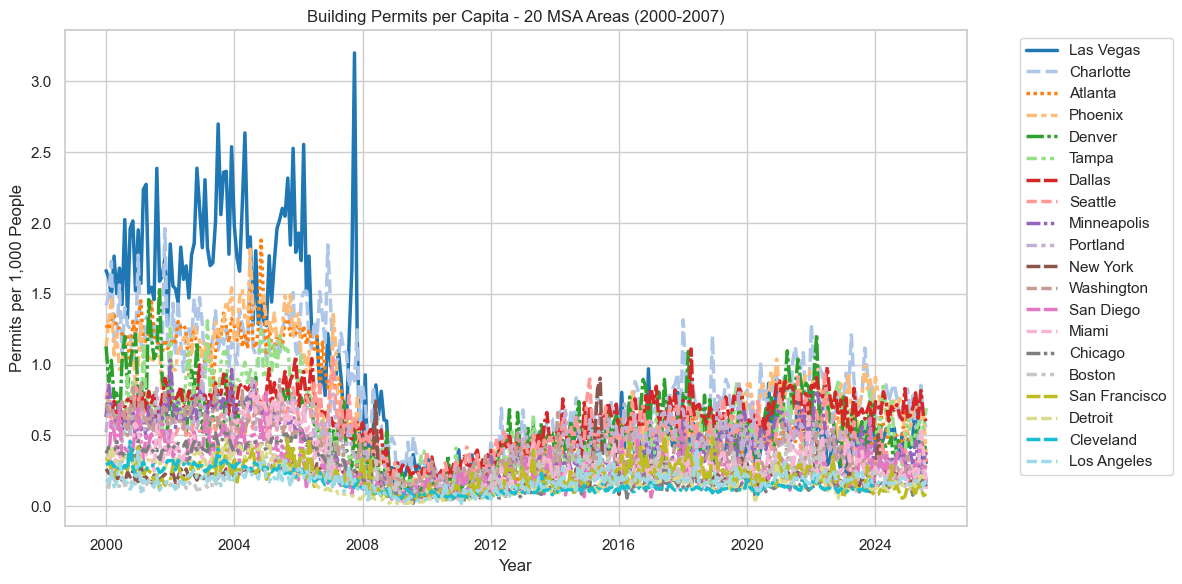

In [5]:
# Calculate Permits per Population
df_ratios = pd.DataFrame(index=df_visuals.index)

# Iterate through the cities to calculate the ratio
for city_lower in msa_columns:
    city_title = city_lower.title()
    
    # Adjust column names based on how they are saved in visual_data.csv
    # In 1_data_download.ipynb, we saved them as:
    # col_name = city.lower() if var_name == 'hpi' else f"{city}_{var_name}"
    # So permits are 'City_permits' and population is 'City_pop'
    
    permits_col = f"{city_title}_permits"
    pop_col = f"{city_title}_pop"
    
    # Check if both series are available in df_visuals
    # Note: In the new structure, both permits and pop are in visual_data.csv
    if permits_col in df_visuals.columns and pop_col in df_visuals.columns:
        permits = df_visuals[permits_col]
        pop = df_visuals[pop_col]
        
        # Population data might be monthly (resampled in download script) or need interpolation
        # If it was already resampled to 'MS' in download script, we can use it directly.
        # Ensure alignment.
        
        # Align population data to the permits index
        pop_aligned = pop.reindex(permits.index).interpolate(method='linear').ffill().bfill()
        
        # Calculate Ratio: Permits / Population
        # Permits are in Units. Population is in Thousands.
        # Result is Units per 1,000 people.
        ratio = permits / pop_aligned
        
        df_ratios[city_title] = ratio

# Plot the Ratios
if not df_ratios.empty:
    # Sort columns by their maximum value (descending) to order the legend
    sorted_ratio_cols = df_ratios.max().sort_values(ascending=False).index.tolist()

    plot_series(
        df_ratios[sorted_ratio_cols], 
        title='Building Permits per Capita - 20 MSA Areas (2000-2007)', 
        ylabel='Permits per 1,000 People',
        palette='tab20'
    )
else:
    print("No data available for Permits per Population calculation.")